In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

base = "/content/drive/MyDrive/Depression_Project/EEG_Data_New"

print(os.listdir(base))
print(os.listdir(base+"/H"))
print(os.listdir(base+"/MDD"))
print(os.listdir(base+"/H/EC")[:5])

Mounted at /content/drive
['H', 'MDD']
['EC', 'EO', 'TASK']
['EC', 'EO', 'TASK']
['H S14 EC.edf', 'H S22 EC.edf', 'H S30 EC.edf', 'H S19 EC.edf', 'H S9 EC.edf']


In [ ]:
!pip install -q mne pyedflib tensorflow scikit-learn matplotlib seaborn pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 70.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
!pip install -q jedi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 64.2 MB/s eta 0:00:00


In [ ]:
!pip install -q mne pyedflib tensorflow scikit-learn matplotlib seaborn pandas numpy

In [ ]:
import mne
import tensorflow as tf
import numpy as np
import pandas as pd
import sklearn

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Everything is working!")

TensorFlow: 2.20.0
MNE: 1.12.1
Everything is working!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mne

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    DepthwiseConv2D,
    SeparableConv2D,
    BatchNormalization,
    AveragePooling2D,
    Dropout,
    Flatten,
    Dense,
    Activation
)
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Depression_Project"

folders = [
    "models",
    "results",
    "plots",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_PATH, folder), exist_ok=True)

print("Project folders created!")

Project folders created!


In [ ]:
DATASET_PATH = os.path.join(BASE_PATH, "EEG_Data_New")

healthy_path = os.path.join(DATASET_PATH, "H", "EC")
mdd_path = os.path.join(DATASET_PATH, "MDD", "EC")

print("Healthy Folder :", healthy_path)
print("MDD Folder     :", mdd_path)

Healthy Folder : /content/drive/MyDrive/Depression_Project/EEG_Data_New/H/EC
MDD Folder     : /content/drive/MyDrive/Depression_Project/EEG_Data_New/MDD/EC


In [ ]:
healthy_files = sorted(glob.glob(os.path.join(healthy_path, "*.edf")))
mdd_files = sorted(glob.glob(os.path.join(mdd_path, "*.edf")))

print("Healthy Subjects :", len(healthy_files))
print("MDD Subjects     :", len(mdd_files))
print("Total Subjects   :", len(healthy_files) + len(mdd_files))

Healthy Subjects : 28
MDD Subjects     : 30
Total Subjects   : 58


In [ ]:
# ============================
# EEG Parameters
# ============================

LOW_FREQ = 1
HIGH_FREQ = 40

WINDOW_SECONDS = 4
OVERLAP = 0.5

all_data = []
all_labels = []

print("Parameters Loaded Successfully")

Parameters Loaded Successfully


In [ ]:
def process_edf(file_path, label):
    """
    Reads one EDF file and converts it into
    normalized 4-second EEG windows.
    """

    raw = mne.io.read_raw_edf(file_path,
                              preload=True,
                              verbose=False)

    # Band-pass filter
    raw.filter(
        l_freq=LOW_FREQ,
        h_freq=HIGH_FREQ,
        verbose=False
    )

    # Get EEG signal
    data = raw.get_data()

    # Normalization (per channel)
    mean = np.mean(data, axis=1, keepdims=True)
    std = np.std(data, axis=1, keepdims=True)

    data = (data - mean) / (std + 1e-8)

    sfreq = int(raw.info["sfreq"])

    window_size = WINDOW_SECONDS * sfreq
    step_size = int(window_size * (1 - OVERLAP))

    for start in range(
        0,
        data.shape[1] - window_size,
        step_size
    ):
        end = start + window_size

        segment = data[:, start:end]

        all_data.append(segment)
        all_labels.append(label)

In [ ]:
print("Loading Healthy Subjects...")

for file in healthy_files:
    process_edf(file, 0)

print("Healthy Subjects Loaded")

Loading Healthy Subjects...
Healthy Subjects Loaded


In [ ]:
print("Loading MDD Subjects...")

for file in mdd_files:
    process_edf(file, 1)

print("MDD Subjects Loaded")

Loading MDD Subjects...
MDD Subjects Loaded


In [ ]:
X = np.array(all_data, dtype=np.float32)
y = np.array(all_labels)

print("Shape of X :", X.shape)
print("Shape of y :", y.shape)

print("Healthy Windows :", np.sum(y == 0))
print("MDD Windows :", np.sum(y == 1))

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (8589,) + inhomogeneous part.

In [ ]:
# Check the shapes of all windows

shapes = {}

for segment in all_data:
    shape = segment.shape
    shapes[shape] = shapes.get(shape, 0) + 1

print("Unique Shapes Found:")
for shape, count in shapes.items():
    print(shape, ":", count)

Unique Shapes Found:
(22, 1024) : 3495
(20, 1024) : 5094


In [ ]:
# Check sampling frequencies

sfreqs = set()

for file in healthy_files + mdd_files:
    raw = mne.io.read_raw_edf(file, preload=False, verbose=False)
    sfreqs.add(raw.info["sfreq"])

print("Sampling Frequencies:", sfreqs)

Sampling Frequencies: {256.0}


In [ ]:
# Check channel counts in every EDF file

channel_counts = {}

for file in healthy_files + mdd_files:
    raw = mne.io.read_raw_edf(file, preload=False, verbose=False)
    n_channels = len(raw.ch_names)
    channel_counts[n_channels] = channel_counts.get(n_channels, 0) + 1

print("Channel Counts:")
print(channel_counts)

Channel Counts:
{22: 23, 20: 35}


In [ ]:
# Check unique window shapes

unique_shapes = {}

for segment in all_data:
    unique_shapes[segment.shape] = unique_shapes.get(segment.shape, 0) + 1

print("Unique Shapes:")
for shape, count in unique_shapes.items():
    print(shape, ":", count)

Unique Shapes:
(22, 1024) : 3495
(20, 1024) : 5094


In [ ]:
all_data = []
all_labels = []

In [ ]:
COMMON_CHANNELS = [
    'Fp1','Fp2',
    'F3','F4',
    'C3','C4',
    'P3','P4',
    'O1','O2',
    'F7','F8',
    'T3','T4',
    'T5','T6',
    'Fz','Cz','Pz'
]

def process_edf(file_path, label):

    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

    # Keep only channels that exist in this file
    available = [ch for ch in COMMON_CHANNELS if ch in raw.ch_names]

    raw.pick(available)

    raw.filter(
        l_freq=1,
        h_freq=40,
        verbose=False
    )

    data = raw.get_data()

    # Z-score normalization
    data = (data - data.mean(axis=1, keepdims=True)) / (
        data.std(axis=1, keepdims=True) + 1e-8
    )

    sfreq = int(raw.info["sfreq"])

    window_size = sfreq * 4
    step = window_size // 2

    for start in range(0, data.shape[1] - window_size + 1, step):
        segment = data[:, start:start + window_size]

        # Only keep windows with exactly 20 channels
        if segment.shape == (20, 1024):
            all_data.append(segment)
            all_labels.append(label)

In [ ]:
print("Loading Healthy...")
for file in healthy_files:
    process_edf(file, 0)

print("Loading MDD...")
for file in mdd_files:
    process_edf(file, 1)

Loading Healthy...


ValueError: No appropriate channels found for the given picks ([])

In [ ]:
import mne

raw = mne.io.read_raw_edf(healthy_files[0], preload=False, verbose=False)

print("Number of channels:", len(raw.ch_names))
print("\nChannel names:\n")
for ch in raw.ch_names:
    print(ch)

Number of channels: 22

Channel names:

EEG Fp1-LE
EEG F3-LE
EEG C3-LE
EEG P3-LE
EEG O1-LE
EEG F7-LE
EEG T3-LE
EEG T5-LE
EEG Fz-LE
EEG Fp2-LE
EEG F4-LE
EEG C4-LE
EEG P4-LE
EEG O2-LE
EEG F8-LE
EEG T4-LE
EEG T6-LE
EEG Cz-LE
EEG Pz-LE
EEG A2-A1
EEG 23A-23R
EEG 24A-24R


In [ ]:
raw.pick(COMMON_CHANNELS)

ValueError: picks (['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']) could not be interpreted as channel names (no channel "[np.str_('Fp1'), np.str_('Fp2'), np.str_('F3'), np.str_('F4'), np.str_('C3'), np.str_('C4'), np.str_('P3'), np.str_('P4'), np.str_('O1'), np.str_('O2'), np.str_('F7'), np.str_('F8'), np.str_('T3'), np.str_('T4'), np.str_('T5'), np.str_('T6'), np.str_('Fz'), np.str_('Cz'), np.str_('Pz')]"), channel types (no type "Fp1" present), or a generic type (just "all" or "data")

In [ ]:
EEG_CHANNELS = [
    "EEG Fp1-LE",
    "EEG F3-LE",
    "EEG C3-LE",
    "EEG P3-LE",
    "EEG O1-LE",
    "EEG F7-LE",
    "EEG T3-LE",
    "EEG T5-LE",
    "EEG Fz-LE",
    "EEG Fp2-LE",
    "EEG F4-LE",
    "EEG C4-LE",
    "EEG P4-LE",
    "EEG O2-LE",
    "EEG F8-LE",
    "EEG T4-LE",
    "EEG T6-LE",
    "EEG Cz-LE",
    "EEG Pz-LE"
]

def process_edf(file_path, label):

    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

    # Pick only EEG channels
    raw.pick_channels(EEG_CHANNELS)

    # Band-pass filter
    raw.filter(1, 40, verbose=False)

    data = raw.get_data()

    # Z-score normalization
    data = (data - data.mean(axis=1, keepdims=True)) / (
        data.std(axis=1, keepdims=True) + 1e-8
    )

    sfreq = int(raw.info["sfreq"])

    window_size = sfreq * 4
    step = window_size // 2

    for start in range(0, data.shape[1] - window_size + 1, step):

        segment = data[:, start:start + window_size]

        if segment.shape == (19, 1024):
            all_data.append(segment)
            all_labels.append(label)

In [ ]:
all_data = []
all_labels = []

print("Loading Healthy...")
for file in healthy_files:
    process_edf(file, 0)

print("Loading MDD...")
for file in mdd_files:
    process_edf(file, 1)

print("Done!")

Loading Healthy...
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels()

In [ ]:
X = np.array(all_data, dtype=np.float32)
y = np.array(all_labels)

print("X Shape :", X.shape)
print("y Shape :", y.shape)

X Shape : (8620, 19, 1024)
y Shape : (8620,)


In [ ]:
import numpy as np

X = np.array(all_data, dtype=np.float32)
y = np.array(all_labels)

print("X Shape :", X.shape)
print("y Shape :", y.shape)

print("\nHealthy Samples :", np.sum(y == 0))
print("MDD Samples     :", np.sum(y == 1))

X Shape : (8620, 19, 1024)
y Shape : (8620,)

Healthy Samples : 4247
MDD Samples     : 4373


In [ ]:
from sklearn.model_selection import train_test_split

# Add channel dimension for EEGNet
X = X[..., np.newaxis]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (6896, 19, 1024, 1)
Testing Shape  : (1724, 19, 1024, 1)


In [ ]:
!pip -q install git+https://github.com/vlawhern/arl-eegmodels.git

ERROR: git+https://github.com/vlawhern/arl-eegmodels.git does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.


In [ ]:
!git clone https://github.com/vlawhern/arl-eegmodels.git

Cloning into 'arl-eegmodels'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 112 (delta 18), reused 17 (delta 17), pack-reused 92 (from 1)
Receiving objects: 100% (112/112), 74.28 KiB | 667.00 KiB/s, done.
Resolving deltas: 100% (50/50), done.


In [ ]:
import sys
sys.path.append("/content/arl-eegmodels")


In [ ]:
from EEGModels import EEGNet

In [ ]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

model = EEGNet(
    nb_classes=2,
    Chans=19,
    Samples=1024,
    dropoutRate=0.5,
    kernLength=64,
    F1=8,
    D=2,
    F2=16,
    norm_rate=0.25,
    dropoutType='Dropout'
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 19, 1024, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 19, 1024, 8)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 19, 1024, 8)    │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 1, 1024, 16)    │           304 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 1024, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 1024, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 256, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 256, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 1, 256, 16)     │           512 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1, 256, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1, 256, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 32, 16)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 32, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         1,026 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Activation)            │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,514 (9.82 KB)

 Trainable params: 2,434 (9.51 KB)

 Non-trainable params: 80 (320.00 B)

In [ ]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

import os

SAVE_PATH = "/content/drive/MyDrive/Depression_Project/saved_models"
os.makedirs(SAVE_PATH, exist_ok=True)

checkpoint = ModelCheckpoint(
    filepath=os.path.join(SAVE_PATH, "best_model.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

earlystop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    verbose=1
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[
        checkpoint,
        earlystop,
        reduce_lr
    ],
    shuffle=True,
    verbose=1
)

Epoch 1/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 717ms/step - accuracy: 0.6919 - loss: 0.5654
Epoch 1: val_accuracy improved from None to 0.89783, saving model to /content/drive/MyDrive/Depression_Project/saved_models/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Depression_Project/saved_models/best_model.keras
173/173 ━━━━━━━━━━━━━━━━━━━━ 135s 742ms/step - accuracy: 0.7942 - loss: 0.4361 - val_accuracy: 0.8978 - val_loss: 0.3801 - learning_rate: 0.0010
Epoch 2/50
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 621ms/step - accuracy: 0.9059 - loss: 0.2540
Epoch 2: val_accuracy improved from 0.89783 to 0.94058, saving model to /content/drive/MyDrive/Depression_Project/saved_models/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Depression_Project/saved_models/best_model.keras
173/173 ━━━━━━━━━━━━━━━━━━━━ 131s 681ms/step - accuracy: 0.9110 - loss: 0.2393 - val_accuracy: 0.9406 - val_loss: 0.1959 - learning_rate: 0.0010
Epoch 3/50
173/173 ━━━━━━━━━━━━━━━━

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"\nTest Accuracy : {test_accuracy*100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.9983 - loss: 0.0098

Test Accuracy : 99.83%
Test Loss     : 0.0098


In [ ]:
model.save(os.path.join(SAVE_PATH, "final_model.keras"))
model.save(os.path.join(SAVE_PATH, "final_model.h5"))

print("✅ Final model saved successfully!")

✅ Final model saved successfully!


In [ ]:
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(SAVE_PATH, "training_history.csv"),
    index=False
)

print("✅ Training history saved.")

✅ Training history saved.


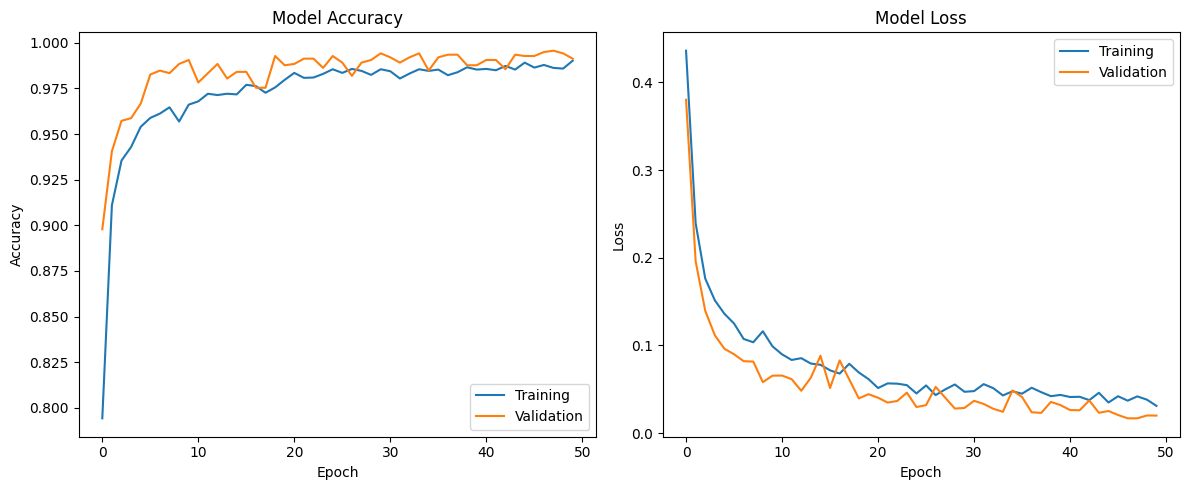

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import json

label_map = {
    0: "Healthy",
    1: "MDD"
}

with open(os.path.join(SAVE_PATH, "labels.json"), "w") as f:
    json.dump(label_map, f)

print("✅ Label mapping saved.")

✅ Label mapping saved.


In [ ]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (6896, 19, 1024, 1)
Test shape: (1724, 19, 1024, 1)


In [ ]:
import os

SAVE_PATH = "/content/drive/MyDrive/Depression_Project/saved_models"

print(os.listdir(SAVE_PATH))

['best_model.keras', 'final_model.keras', 'final_model.h5', 'training_history.csv', 'labels.json']


54/54 ━━━━━━━━━━━━━━━━━━━━ 14s 250ms/step


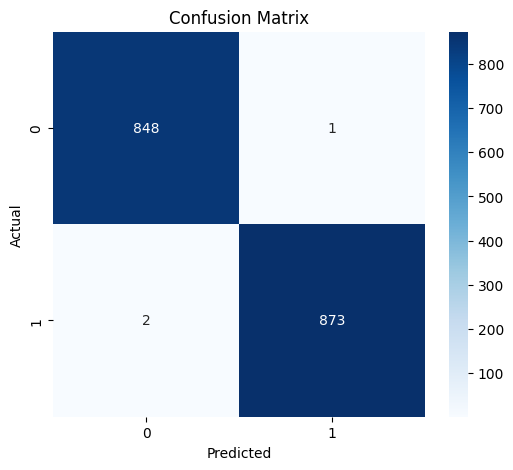

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_pred = y_pred.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig(
    "/content/drive/MyDrive/Depression_Project/saved_models/confusion_matrix.png"
)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
y_pred = y_pred.argmax(axis=1)

print(classification_report(y_test, y_pred,
                            target_names=["Healthy", "MDD"]))

54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 212ms/step
              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00       849
         MDD       1.00      1.00      1.00       875

    accuracy                           1.00      1724
   macro avg       1.00      1.00      1.00      1724
weighted avg       1.00      1.00      1.00      1724



54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step


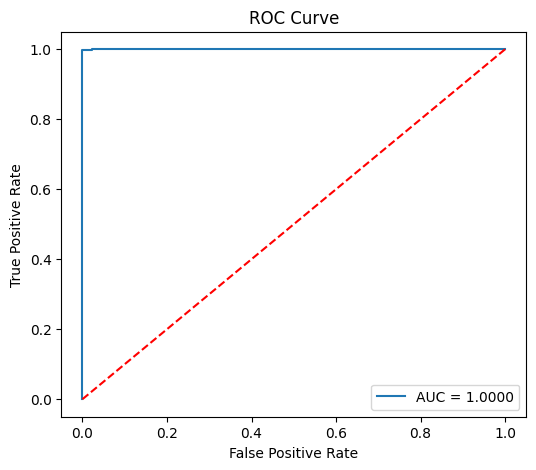

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_prob = model.predict(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("/content/drive/MyDrive/Depression_Project/saved_models/roc_curve.png")
plt.show()

In [ ]:
from tensorflow.keras.models import load_model

model = load_model(
    "/content/drive/MyDrive/Depression_Project/saved_models/best_model.keras"
)

print("Model Loaded Successfully!")

Model Loaded Successfully!
